In [1]:
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
train_df = pd.read_csv('D:\Artificial Intelligence\Deep Learning\Datasets\mnist\mtrain.csv')
train_df

<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_19072\3389648312.py:1: SyntaxWarning: invalid escape sequence '\A'
  train_df = pd.read_csv('D:\Artificial Intelligence\Deep Learning\Datasets\mnist\mtrain.csv')


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
train_df.label.value_counts()

label
1    4684
7    4401
3    4351
9    4188
2    4177
6    4137
0    4132
4    4072
8    4063
5    3795
Name: count, dtype: int64

In [4]:
test_df = pd.read_csv('D:\Artificial Intelligence\Deep Learning\Datasets\mnist\mtest.csv')
test_df

<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_19072\3378694372.py:1: SyntaxWarning: invalid escape sequence '\A'
  test_df = pd.read_csv('D:\Artificial Intelligence\Deep Learning\Datasets\mnist\mtest.csv')


,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
print("Train data shape: {}\nTest Data Shape: {}".format(train_df.shape, test_df.shape))

Train data shape: (42000, 785)
Test Data Shape: (28000, 784)


In [6]:
X_train = train_df.drop("label", axis = 1)
Y_train = train_df["label"]
X_test = test_df
print(X_train.shape, Y_train.shape, X_test.shape)

(42000, 784) (42000,) (28000, 784)


In [7]:
X_train = X_train/225
X_test = X_test/225

In [8]:
X_train = X_train.values
Y_train = Y_train.values
X_test = X_test.values

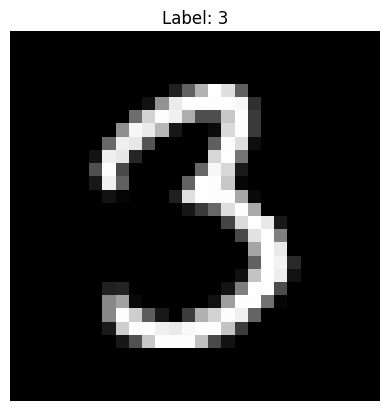

In [9]:
idx = np.random.randint(0, len(X_train))
image = X_train[idx].reshape(28, 28)

plt.imshow(image, cmap = 'gray')
plt.title(f"Label: {Y_train[idx]}")
plt.axis('off')
plt.show()

In [10]:
model = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape = (784,)),

    keras.layers.Dense(64, activation='relu'),

    keras.layers.Dense(64, activation='softmax')
])

print("\nModel Summary")
model.summary()

c:\Users\HASEEB\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Model Summary


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,896 (441.00 KB)

 Trainable params: 112,896 (441.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [12]:
history = model.fit(
    X_train, Y_train,
    epochs = 10,
    batch_size = 32
)

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9085 - loss: 0.3208
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.9607 - loss: 0.1309
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9723 - loss: 0.0914
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.9782 - loss: 0.0680
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9830 - loss: 0.0530
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9854 - loss: 0.0434
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.9888 - loss: 0.0342
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.9907 - loss: 0.0285
Epoch 9/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.9915 - loss: 0.0248
Epoch 10/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.9930 - loss: 0.0204


In [13]:
predictions = model.predict(X_test)

pred_labels = np.argmax(predictions, axis = 1)
print("\nFirst 10 Predictions: ")
print(pred_labels[:10])

875/875 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step

First 10 Predictions: 
[2 0 9 9 3 7 0 3 0 3]


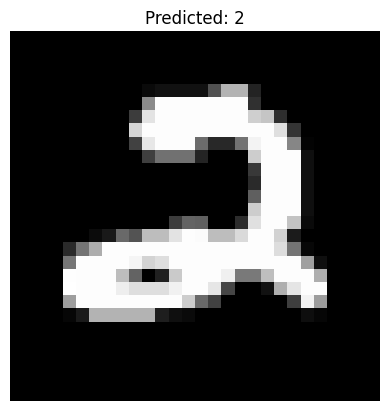

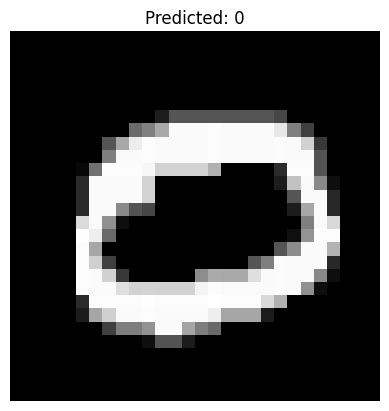

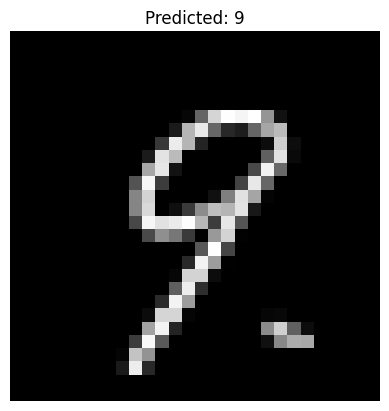

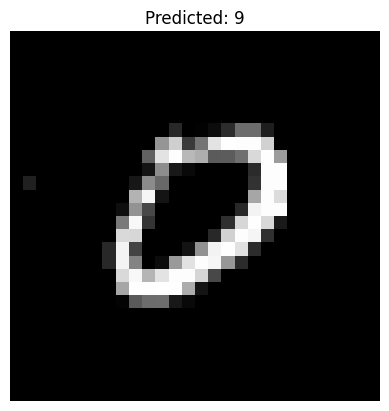

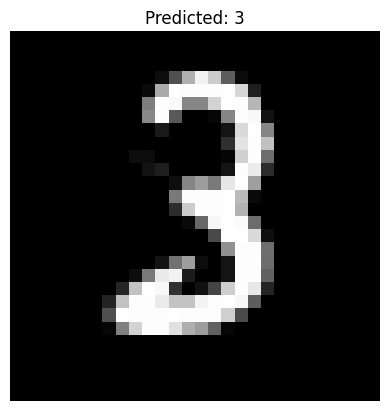

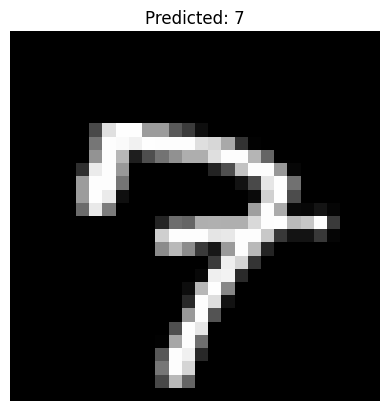

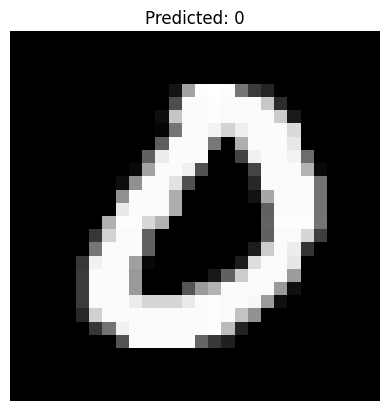

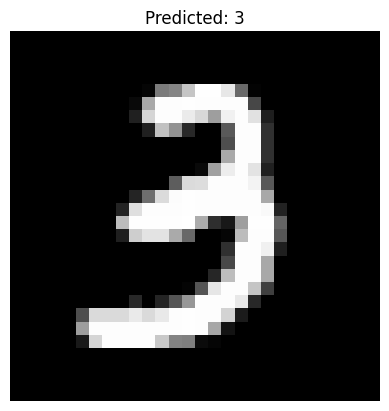

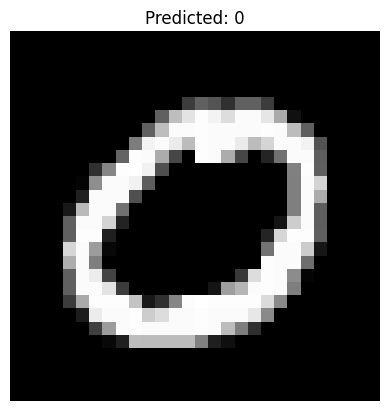

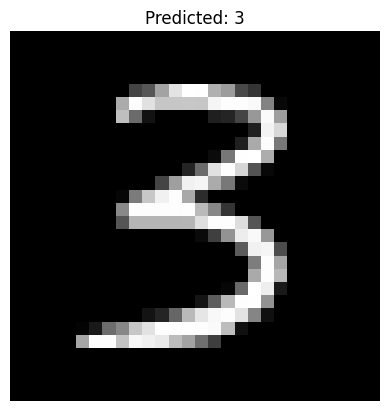

In [14]:
for i in range(10):
    image = X_test[i].reshape(28, 28)

    plt.imshow(image, cmap = 'gray')
    plt.title(f"Predicted: {pred_labels[i]}")
    plt.axis('off')
    plt.show()

In [15]:
final_acc = history.history['accuracy'][-1]
final_loss = history.history['loss'][-1]

print("\nFinal Training Accuracy: ", final_acc)
print("Final Training Loss: ", final_loss)


Final Training Accuracy:  0.992976188659668
Final Training Loss:  0.020436320453882217


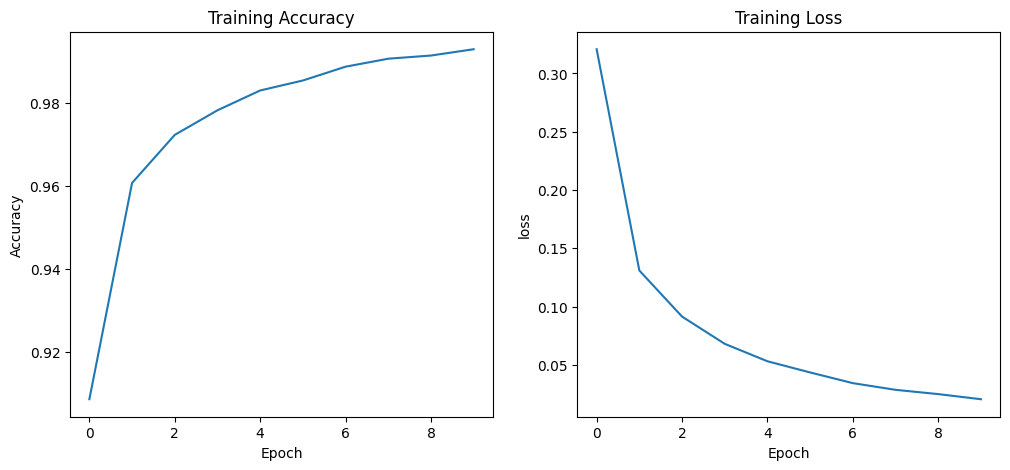

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("loss")

plt.show()

In [17]:
model.save("mnist_mlp_model.h5")
print("Model saved successfully!")

Model saved successfully!


In [19]:
from tensorflow import keras
loaded_model = keras.models.load_model("D:\Artificial Intelligence\Deep Learning\Model Practice\mnist_mlp_model.h5")
print("Model loaded Successfully!")

<>:2: SyntaxWarning: invalid escape sequence '\A'
<>:2: SyntaxWarning: invalid escape sequence '\A'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_19072\3099968054.py:2: SyntaxWarning: invalid escape sequence '\A'
  loaded_model = keras.models.load_model("D:\Artificial Intelligence\Deep Learning\Model Practice\mnist_mlp_model.h5")


Model loaded Successfully!


In [20]:
predictions = loaded_model.predict(X_test)

pred_labels = np.argmax(predictions, axis = 1)

print("First 10 Predictions: ")
print(pred_labels[:10])

875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
First 10 Predictions: 
[2 0 9 9 3 7 0 3 0 3]


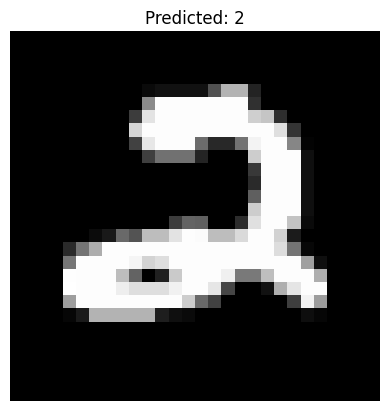

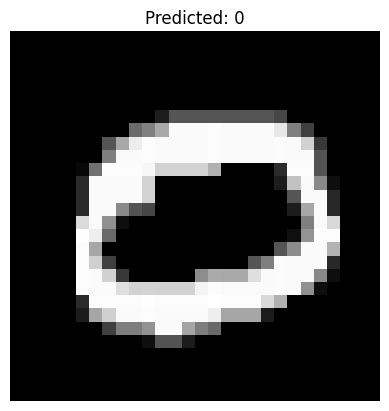

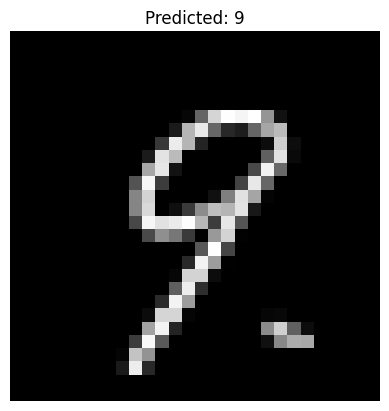

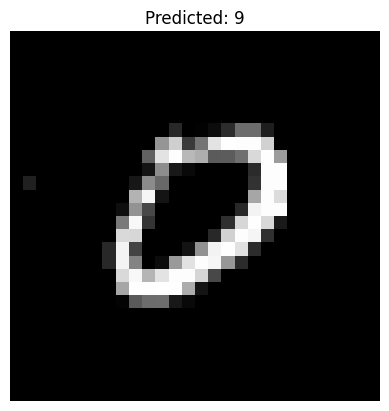

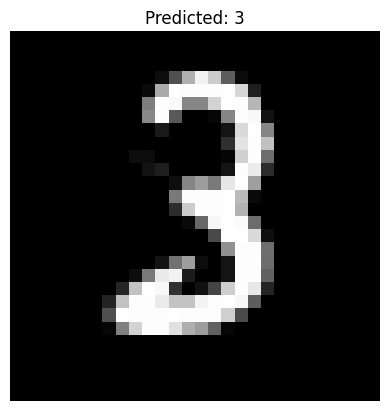

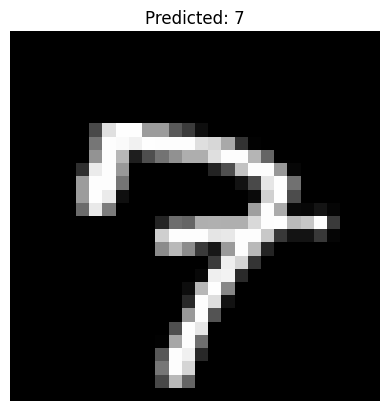

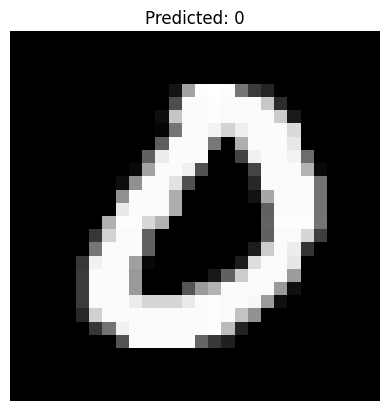

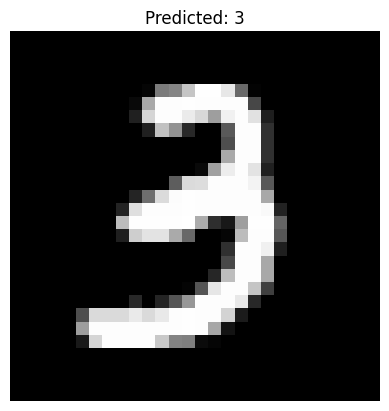

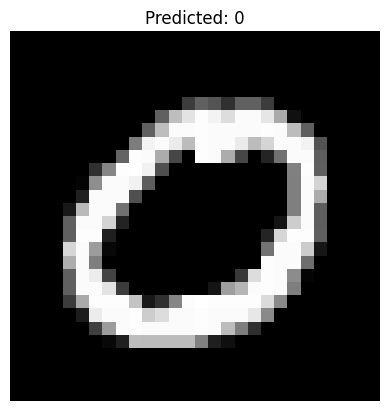

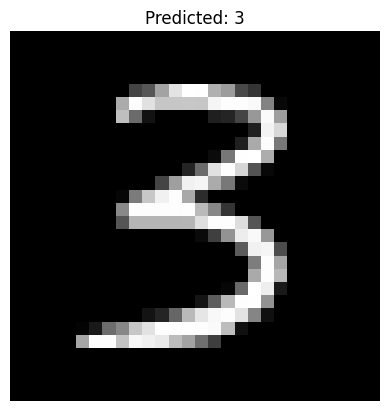

In [21]:
import matplotlib.pyplot as plt

for i in range(10):
    image = X_test[i].reshape(28, 28)

    plt.imshow(image, cmap = 'gray')
    plt.title(f"Predicted: {pred_labels[i]}")
    plt.axis('off')
    plt.show()